# Assignment 3: Lexical Analysis and Automatic Genre Classification Using Genius Song Lyrics

**Dataset:** Genius Song Lyrics from Kaggle (CSV)


## 1. Import libraries

In [1]:
%pip install pandas numpy matplotlib seaborn nltk scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [13]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from collections import Counter
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Скачиваем список стоп-слов
nltk.download("stopwords")

# Скачиваем необходимые ресурсы для лемматизации и токенизации
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Daniyar\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Daniyar\AppData\Roaming\nltk_data...
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Daniyar\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Daniyar\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 2. Load a manageable sample from the large CSV

The original dataset has millions of rows. Loading every full lyric into memory may be slow or exceed available RAM. This cell reads the CSV in chunks, keeps only the columns needed, filters for `pop` and `rap` and English-language rows, and uses reservoir sampling to keep a balanced sample.


In [30]:
import pandas as pd
import numpy as np

CSV_PATH = "data/song_lyrics.csv"  # Change this to your actual CSV filename
TARGET_GENRES = ["pop", "rap"]
SAMPLES_PER_GENRE = 1500  
CHUNK_SIZE = 100_000
SEED = 42  # <--- Добавили SEED

# Read only the columns needed for the analysis.
header = pd.read_csv(CSV_PATH, nrows=0)
available_columns = header.columns.tolist()
required = ["lyrics", "tag"]
missing = [c for c in required if c not in available_columns]
if missing:
    raise ValueError(f"Required columns missing: {missing}. Available columns: {available_columns}")

usecols = [c for c in ["lyrics", "tag", "language_cld3", "language_ft", "title", "artist", "year"] if c in available_columns]
reservoir = {genre: [] for genre in TARGET_GENRES}
seen = {genre: 0 for genre in TARGET_GENRES}
rng = np.random.default_rng(SEED)

for chunk_number, chunk in enumerate(pd.read_csv(CSV_PATH, usecols=usecols, chunksize=CHUNK_SIZE, low_memory=False), start=1):
    chunk["tag"] = chunk["tag"].astype("string").str.strip().str.lower()
    chunk = chunk[chunk["tag"].isin(TARGET_GENRES)]

    language_cols = [c for c in ["language_cld3", "language_ft"] if c in chunk.columns]
    if language_cols:
        english_mask = pd.Series(False, index=chunk.index)
        for col in language_cols:
            english_mask |= chunk[col].astype("string").str.lower().eq("en")
        chunk = chunk[english_mask]

    chunk = chunk.dropna(subset=["lyrics"])
    chunk = chunk[chunk["lyrics"].astype(str).str.strip().ne("")]

    for row in chunk[["lyrics", "tag"]].itertuples(index=False, name=None):
        genre = row[1]
        seen[genre] += 1
        item = {"lyrics": str(row[0]), "genre": genre}
        if len(reservoir[genre]) < SAMPLES_PER_GENRE:
            reservoir[genre].append(item)
        else:
            j = int(rng.integers(0, seen[genre]))
            if j < SAMPLES_PER_GENRE:
                reservoir[genre][j] = item

    if chunk_number % 10 == 0:
        print(f"Read {chunk_number * CHUNK_SIZE:,} rows; sampled counts: " + str({g: len(reservoir[g]) for g in TARGET_GENRES}))

data = pd.DataFrame(reservoir["pop"] + reservoir["rap"])
data = data.drop_duplicates(subset=["lyrics"]).reset_index(drop=True)

print("Rows encountered by genre (after language filtering):", seen)
print("Sampled dataset shape:", data.shape)
print("Genre counts:")
print(data["genre"].value_counts().to_frame("Songs"))
display(data.head())

Read 1,000,000 rows; sampled counts: {'pop': 1500, 'rap': 1500}
Read 2,000,000 rows; sampled counts: {'pop': 1500, 'rap': 1500}
Read 3,000,000 rows; sampled counts: {'pop': 1500, 'rap': 1500}
Read 4,000,000 rows; sampled counts: {'pop': 1500, 'rap': 1500}
Read 5,000,000 rows; sampled counts: {'pop': 1500, 'rap': 1500}
Rows encountered by genre (after language filtering): {'pop': 1424238, 'rap': 983161}
Sampled dataset shape: (3000, 2)
Genre counts:
       Songs
genre       
pop     1500
rap     1500


,lyrics,genre
0,Repeat and rewind\nI'm not going there this ti...,pop
1,Told my troubled heart don’t worry\nHope is he...,pop
2,"Walk away!\n\nRound one, a girl, a weight upon...",pop
3,Death is so sad\nDeath is so sad\nDeath is so ...,pop
4,Can we go away\nAnd never turn around again\nO...,pop


## 4. Check the sample size

Reservoir sampling aims to create a sample of up to 1,500 songs per genre from the full file. Duplicate lyrics may reduce the final count slightly. A balanced sample makes the model comparison easier to interpret.


In [31]:
display(data["genre"].value_counts().to_frame("Songs"))
if data["genre"].nunique() < 2:
    raise ValueError("Both pop and rap must be present. Check the tag labels and language columns in your CSV.")
if data["genre"].value_counts().min() < 50:
    raise ValueError("There are too few rows in at least one genre. Increase the sample size or check filtering.")


,Songs
genre,
pop,1500
rap,1500


### 4.1 Genre distribution

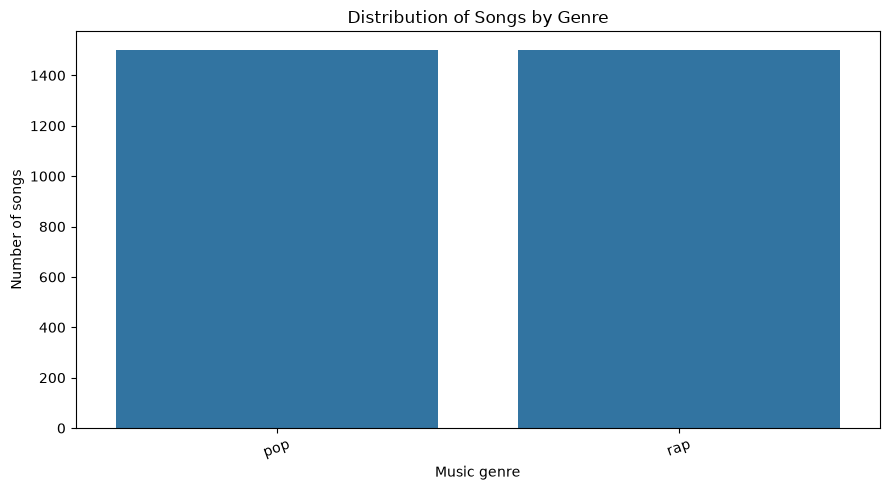

In [32]:
plt.figure(figsize=(9, 5))
sns.countplot(data=data, x="genre", order=data["genre"].value_counts().index)
plt.title("Distribution of Songs by Genre")
plt.xlabel("Music genre")
plt.ylabel("Number of songs")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 5. Text preprocessing
The preprocessing lowercases text, removes punctuation and non-English characters, tokenizes by whitespace, removes English stop words, and lemmatizes words. This simplifies lexical analysis, but can remove stylistic information such as repetitions, slang, or informal spelling.

In [33]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z'\s]", " ", text)
    tokens = text.split()
    tokens = [w for w in tokens if w not in stop_words and len(w) > 1]
    return [lemmatizer.lemmatize(w) for w in tokens]

data["tokens"] = data["lyrics"].apply(preprocess_text)
data["clean_lyrics"] = data["tokens"].apply(lambda tokens: " ".join(tokens))
data["word_count"] = data["tokens"].apply(len)

display(data[["genre", "lyrics", "clean_lyrics"]].head())
display(data.groupby("genre")["word_count"].mean().round(2).to_frame("Average processed words"))

,genre,lyrics,clean_lyrics
0,pop,Repeat and rewind\nI'm not going there this ti...,repeat rewind going time could make plan go ho...
1,pop,Told my troubled heart don’t worry\nHope is he...,told troubled heart worry hope tide turning se...
2,pop,"Walk away!\n\nRound one, a girl, a weight upon...",walk away round one girl weight upon shoulder ...
3,pop,Death is so sad\nDeath is so sad\nDeath is so ...,death sad death sad death sad happens thing ge...
4,pop,Can we go away\nAnd never turn around again\nO...,go away never turn around escapade always keep...


,Average processed words
genre,
pop,111.40
rap,238.58


### 5.1 Lyrics length by genre

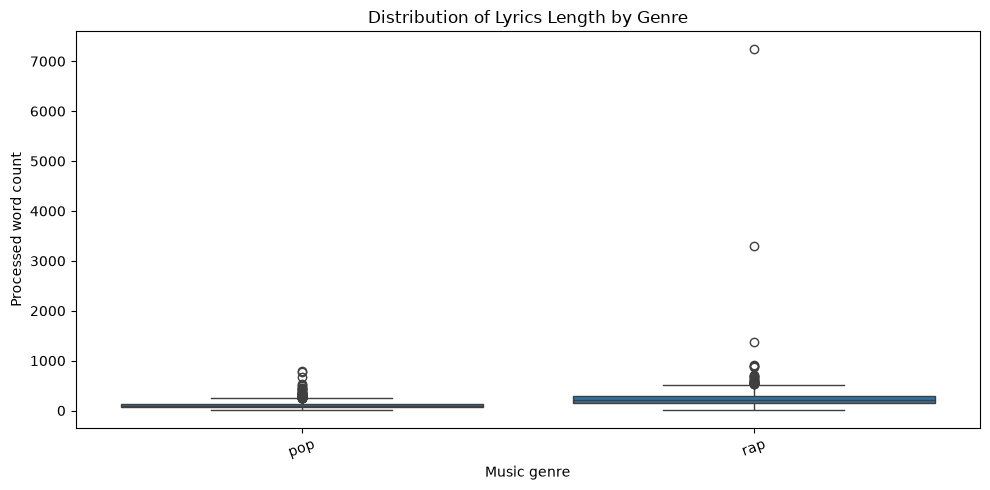

In [34]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=data, x="genre", y="word_count")
plt.title("Distribution of Lyrics Length by Genre")
plt.xlabel("Music genre")
plt.ylabel("Processed word count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 6. Frequency analysis
For each genre, calculate the ten most frequent words, their absolute counts, and relative frequencies per total processed words.

In [35]:
genre_counters = {}
genre_total_words = {}

for genre in sorted(data["genre"].unique()):
    tokens = [token for row in data.loc[data["genre"] == genre, "tokens"] for token in row]
    genre_counters[genre] = Counter(tokens)
    genre_total_words[genre] = len(tokens)

top_words_rows = []
for genre, counter in genre_counters.items():
    total_words = genre_total_words[genre]
    for word, count in counter.most_common(10):
        top_words_rows.append({
            "Genre": genre,
            "Word": word,
            "Absolute Frequency": count,
            "Relative Frequency (%)": count / total_words * 100 if total_words else 0
        })

top_words_df = pd.DataFrame(top_words_rows)
display(top_words_df.round(4))

,Genre,Word,Absolute Frequency,Relative Frequency (%)
0,pop,know,2392,1.4314
1,pop,oh,2135,1.2776
2,pop,love,1966,1.1765
3,pop,like,1789,1.0706
4,pop,chorus,1450,0.8677
5,pop,go,1347,0.8061
6,pop,time,1323,0.7917
7,pop,yeah,1296,0.7756
8,pop,one,1178,0.7049
9,pop,got,1138,0.6810


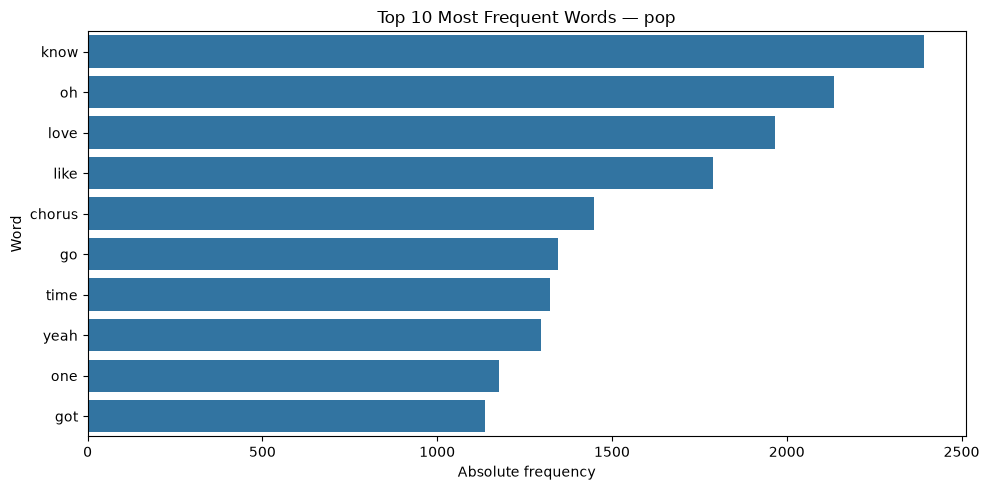

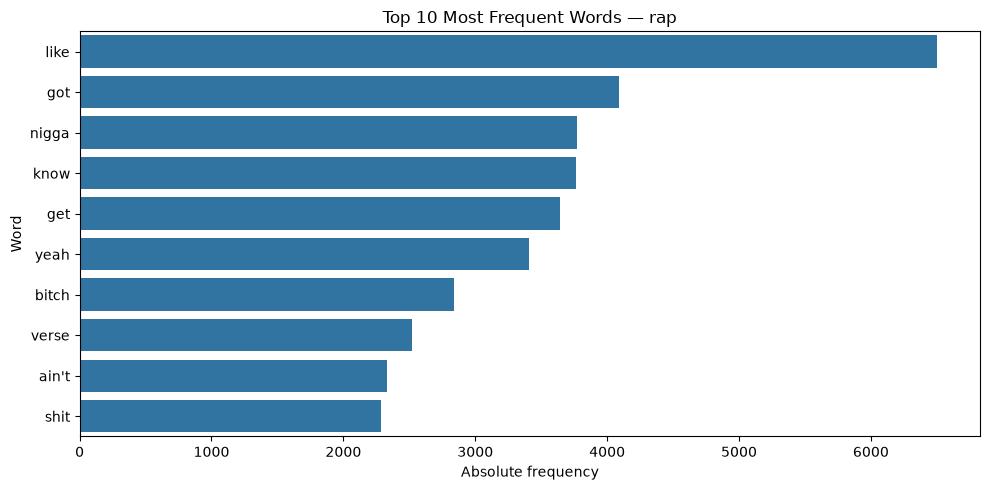

In [36]:
for genre in sorted(genre_counters):
    top_words = genre_counters[genre].most_common(10)
    words = [x[0] for x in top_words]
    counts = [x[1] for x in top_words]
    plt.figure(figsize=(10, 5))
    sns.barplot(x=counts, y=words)
    plt.title(f"Top 10 Most Frequent Words — {genre}")
    plt.xlabel("Absolute frequency")
    plt.ylabel("Word")
    plt.tight_layout()
    plt.show()

## 7. Lexical category analysis
Three example categories are used: time expressions, emotions, and body parts. Frequencies are normalized per 1,000 processed words for fairer comparison between genres.

In [37]:
lexical_categories = {
    "Time expressions": {
        "morning", "evening", "night", "day", "today",
        "tomorrow", "yesterday", "tonight", "forever", "hour"
    },
    "Emotions": {
        "love", "sadness", "happiness", "anger", "happy",
        "sad", "cry", "smile", "fear", "joy", "heartbreak"
    },
    "Body parts": {
        "heart", "eye", "hand", "head", "face",
        "body", "arm", "leg", "skin", "blood"
    }
}

category_rows = []
for genre in sorted(data["genre"].unique()):
    tokens = [token for row in data.loc[data["genre"] == genre, "tokens"] for token in row]
    total_words = len(tokens)
    counter = Counter(tokens)
    for category, words in lexical_categories.items():
        count = sum(counter[word] for word in words)
        category_rows.append({
            "Genre": genre,
            "Category": category,
            "Absolute Frequency": count,
            "Frequency per 1000 Words": count / total_words * 1000 if total_words else 0
        })

category_df = pd.DataFrame(category_rows)
display(category_df.round(3))

,Genre,Category,Absolute Frequency,Frequency per 1000 Words
0,pop,Time expressions,2460,14.721
1,pop,Emotions,2816,16.852
2,pop,Body parts,2804,16.780
3,rap,Time expressions,2433,6.798
4,rap,Emotions,2127,5.943
5,rap,Body parts,3130,8.746


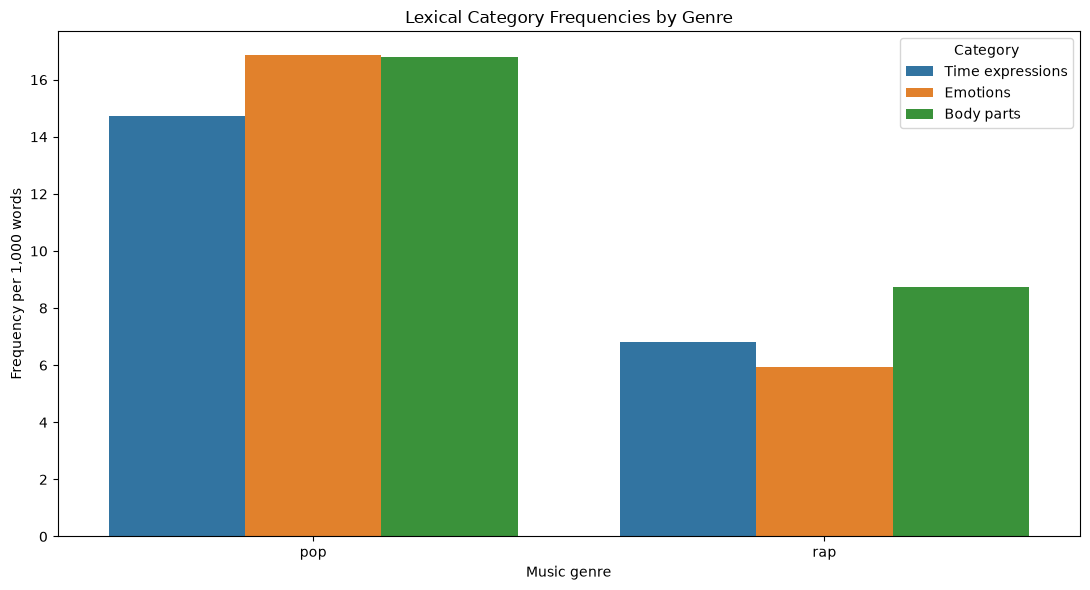

In [38]:
plt.figure(figsize=(11, 6))
sns.barplot(data=category_df, x="Genre", y="Frequency per 1000 Words", hue="Category")
plt.title("Lexical Category Frequencies by Genre")
plt.xlabel("Music genre")
plt.ylabel("Frequency per 1,000 words")
plt.tight_layout()
plt.show()

## 8. Rare words and TF-IDF
Rare words are defined as words occurring no more than three times within the entire genre corpus. TF-IDF scores are used to identify terms that are relatively informative across documents.

In [39]:
rare_words = {}
for genre, counter in genre_counters.items():
    rare_words[genre] = {word: count for word, count in counter.items() if count <= 3}
    print(f"\n{genre}: example rare words (maximum 3 occurrences)")
    print(sorted(rare_words[genre].items(), key=lambda item: (item[1], item[0]))[:20])


pop: example rare words (maximum 3 occurrences)
[("''cause", 1), ("'billz", 1), ("'caine", 1), ("'cchiu", 1), ("'cept", 1), ("'chasing", 1), ("'cowspiracy'", 1), ("'dad", 1), ("'finna", 1), ("'fore", 1), ("'forever", 1), ("'hell", 1), ("'hello's", 1), ("'i", 1), ("'less", 1), ("'ll", 1), ("'lonesome", 1), ("'long", 1), ("'member", 1), ("'nfinu", 1)]

rap: example rare words (maximum 3 occurrences)
[("''", 1), ("''boy", 1), ("''oh", 1), ("''we", 1), ("'ain't", 1), ("'army", 1), ("'avin", 1), ("'backs", 1), ("'bouta", 1), ("'brons", 1), ("'burg", 1), ("'bust's", 1), ("'caiah's", 1), ("'caine", 1), ("'cause'", 1), ("'chetes", 1), ("'cris'", 1), ("'cuzza", 1), ("'d", 1), ("'dear", 1)]


In [40]:
# Exploratory TF-IDF analysis across the selected corpus.
# This is for lexical analysis only; the classifier below fits its vectorizer on training data only.
tfidf_analysis = TfidfVectorizer(
    max_features=10000, min_df=2, max_df=0.95, ngram_range=(1, 2)
)
X_tfidf_all = tfidf_analysis.fit_transform(data["clean_lyrics"])
feature_names = np.array(tfidf_analysis.get_feature_names_out())

mean_tfidf_by_genre = {}
for genre in sorted(data["genre"].unique()):
    row_indices = np.flatnonzero(data["genre"].to_numpy() == genre)
    mean_scores = np.asarray(X_tfidf_all[row_indices].mean(axis=0)).ravel()
    top_indices = mean_scores.argsort()[::-1][:10]
    mean_tfidf_by_genre[genre] = pd.DataFrame({
        "Term": feature_names[top_indices],
        "Mean TF-IDF": mean_scores[top_indices]
    })
    print(f"\nTop characteristic terms for {genre}:")
    display(mean_tfidf_by_genre[genre])


Top characteristic terms for pop:


,Term,Mean TF-IDF
0,love,0.029054
1,oh,0.026707
2,know,0.024034
3,chorus,0.020186
4,time,0.019186
5,like,0.018791
6,never,0.017986
7,one,0.017804
8,go,0.017426
9,see,0.016579



Top characteristic terms for rap:


,Term,Mean TF-IDF
0,like,0.055194
1,nigga,0.052151
2,got,0.038332
3,bitch,0.036633
4,yeah,0.035622
5,get,0.034641
6,know,0.033243
7,shit,0.030629
8,ain,0.027989
9,fuck,0.027172


## 9. Automatic genre classification
Compare TF-IDF + Multinomial Naive Bayes with TF-IDF + Logistic Regression. Use an 80/20 stratified train/test split. Fit TF-IDF on the training set only to prevent data leakage.

In [41]:
X = data["clean_lyrics"]
y = data["genre"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining genre counts:")
display(y_train.value_counts().to_frame("Songs"))
print("\nTesting genre counts:")
display(y_test.value_counts().to_frame("Songs"))

Training samples: 2400
Testing samples: 600

Training genre counts:


,Songs
genre,
rap,1200
pop,1200



Testing genre counts:


,Songs
genre,
rap,300
pop,300


In [42]:
vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (2400, 20000)
Testing matrix: (600, 20000)


In [43]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.5),
    "Logistic Regression": LogisticRegression(
        C=1.0, max_iter=2000, random_state=SEED
    )
}

results = {}
predictions = {}
trained_models = {}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)

    trained_models[name] = model
    predictions[name] = y_pred
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1-score": f1_score(y_test, y_pred, average="macro", zero_division=0)
    }

    print(f"\n{name}")
    print(classification_report(y_test, y_pred, zero_division=0))

results_df = pd.DataFrame(results).T
display(results_df.round(4))


Multinomial Naive Bayes
              precision    recall  f1-score   support

         pop       0.89      0.82      0.85       300
         rap       0.83      0.89      0.86       300

    accuracy                           0.86       600
   macro avg       0.86      0.86      0.86       600
weighted avg       0.86      0.86      0.86       600


Logistic Regression
              precision    recall  f1-score   support

         pop       0.87      0.90      0.89       300
         rap       0.90      0.87      0.88       300

    accuracy                           0.89       600
   macro avg       0.89      0.89      0.89       600
weighted avg       0.89      0.89      0.89       600



,Accuracy,Macro F1-score
Multinomial Naive Bayes,0.8583,0.8582
Logistic Regression,0.8867,0.8866


### 9.1 Model performance comparison

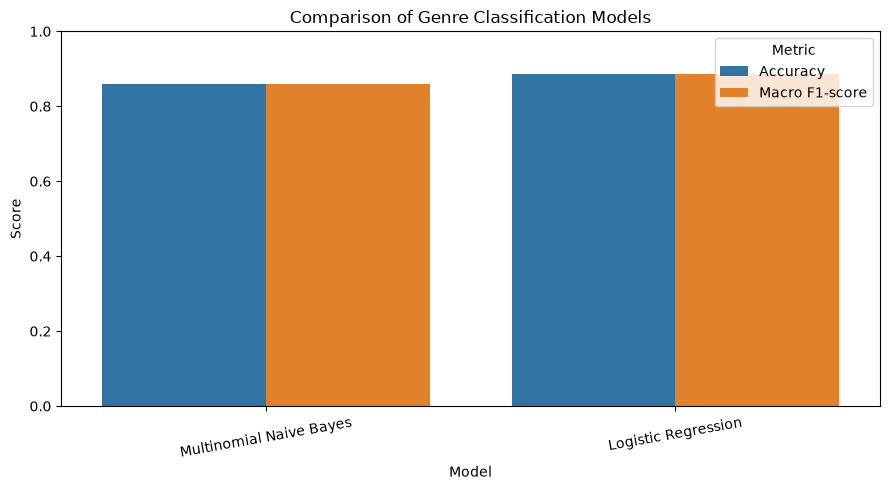

Best model by Macro F1-score: Logistic Regression
Accuracy          0.8867
Macro F1-score    0.8866
Name: Logistic Regression, dtype: float64


In [44]:
results_plot = results_df.reset_index().rename(columns={"index": "Model"})
results_long = results_plot.melt(
    id_vars="Model", var_name="Metric", value_name="Score"
)

plt.figure(figsize=(9, 5))
sns.barplot(data=results_long, x="Model", y="Score", hue="Metric")
plt.title("Comparison of Genre Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

best_model_name = results_df["Macro F1-score"].idxmax()
print("Best model by Macro F1-score:", best_model_name)
print(results_df.loc[best_model_name].round(4))

## 10. Confusion matrices

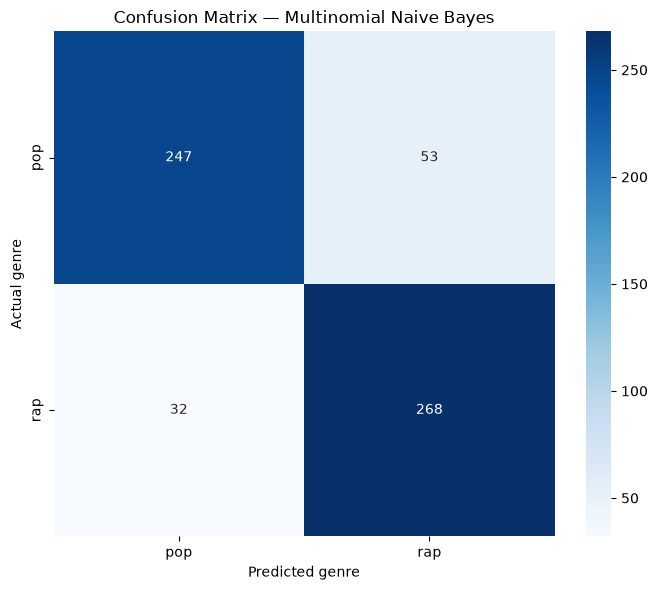

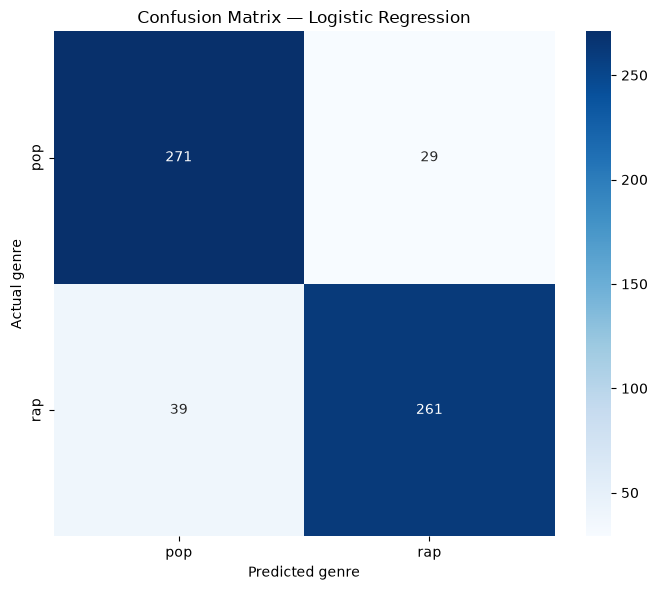

In [45]:
genre_labels = sorted(y.unique())

for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred, labels=genre_labels)
    plt.figure(figsize=(7, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=genre_labels, yticklabels=genre_labels
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted genre")
    plt.ylabel("Actual genre")
    plt.tight_layout()
    plt.show()

## 11. Error analysis
Display at least five test songs misclassified by one or both models. Inspect the actual examples before explaining why they were misclassified.

In [46]:
error_df = pd.DataFrame({
    "Lyrics": X_test,
    "Actual Genre": y_test,
    "Naive Bayes Prediction": predictions["Multinomial Naive Bayes"],
    "Logistic Regression Prediction": predictions["Logistic Regression"]
})

error_df["Naive Bayes Error"] = error_df["Actual Genre"] != error_df["Naive Bayes Prediction"]
error_df["Logistic Regression Error"] = error_df["Actual Genre"] != error_df["Logistic Regression Prediction"]

errors = error_df[error_df["Naive Bayes Error"] | error_df["Logistic Regression Error"]].copy()

print("Songs misclassified by at least one model:", len(errors))
error_preview = errors[[
    "Lyrics", "Actual Genre", "Naive Bayes Prediction", "Logistic Regression Prediction"
]].head(5).copy()

error_preview["Lyrics"] = error_preview["Lyrics"].str.slice(0, 250) + "..."
display(error_preview)

Songs misclassified by at least one model: 102


,Lyrics,Actual Genre,Naive Bayes Prediction,Logistic Regression Prediction
1642,intro tusky verse lay make soul fade tell find...,rap,pop,pop
2961,chorus go go go go right atmosphere go go go g...,rap,pop,pop
1152,love woman im tell truth ain't gonna put way g...,pop,rap,rap
2607,chorus feel like can't catch break though feel...,rap,rap,pop
492,verse walk thinking one seven wonder talking t...,pop,rap,pop


### Error analysis discussion

Misclassification may occur because different genres share themes such as love, relationships, emotions, and personal experiences. Slang, repetition, figurative language, and artist-specific expressions can also affect predictions. The models analyse lyrics rather than rhythm, melody, instrumentation, or vocal style. Some songs may combine multiple genres, so a single label may not fully represent them.

Use the displayed examples and confusion matrices to state which genres are most often confused. Do not claim a specific error pattern unless it is supported by the actual results.

## 12. Conclusion
Run the notebook first, then complete the conclusion using the measured results.

### Conclusion

This project examined lexical differences between pop and rap lyrics in the Genius Song Lyrics dataset from Kaggle. It compared word frequencies, selected lexical categories, rare words, and TF-IDF terms. The notebook also compared Multinomial Naive Bayes and Logistic Regression for automatic genre classification.

**Complete this section after running the notebook:**
- Multinomial Naive Bayes — Accuracy: `___`; Macro F1-score: `___`.
- Logistic Regression — Accuracy: `___`; Macro F1-score: `___`.
- Best model by Macro F1-score: `___`.
- Most useful observed lexical differences: `___`.

The experiment tests whether text alone can distinguish the two labels in this dataset. Its limitations include the use of a sample rather than the entire dataset, possible errors in genre tags or language detection, and the fact that lyrics do not include audio features such as melody, rhythm, instrumentation, or vocal delivery.


## Reproducibility and limitations

- Random seed: `42`.
- CSV is read in chunks to reduce memory use.
- Only `lyrics`, `tag`, and available language metadata are required.
- Target genres: `pop` and `rap`.
- English filtering is applied when `language_cld3` and/or `language_ft` columns are present. A row is kept if at least one available detector labels it `en`.
- Up to 1,500 rows per genre are sampled; exact duplicate lyrics are removed from the sample.
- Train/test split: 80% / 20%, stratified by genre.
- The classification TF-IDF vectorizer is fitted on training data only.
- Lyrics-only classification does not measure the full musical genre.
- Cite the Kaggle dataset page and follow its licensing conditions in the final submission.
